# Calcul des indicateurs climatiques

## objectif:

Transformer les données **journalières** (65744 lignes) en un petit tableau d'indicateurs : **une ligne par ville et par année**.
C'est ce tableau qui ira ensuite dans la table d'entraînement.

## La méthode pour chaque indicateur :
1. **Marquer** : créer une colonne vrai/faux (ou un calcul) pour chaque jour
2. **Regrouper** : `groupby` par ville et par année, puis additionner / moyenner
3. **Vérifier** : est-ce que le résultat est crédible ?

# 1. Chargement

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

villes = ["abidjan", "bouake", "korhogo", "yamoussoukro"]
liste = []

for v in villes:
    d = pd.read_parquet(f"../data/processed/power_{v}_clean.parquet")
    d["ville"] = v
    liste.append(d)

climat = pd.concat(liste, ignore_index=True)
climat["date"] = pd.to_datetime(climat["date"])
climat["mois"] = climat["date"].dt.month
climat = climat.sort_values(["ville", "date"]).reset_index(drop=True)
climat.shape

(65744, 23)

On a trié par ville puis par date (`sort_values`). C'est important pour la plus longue série de jours secs : il faut que les jours soient **dans l'ordre**.

# 2. Les choix à documenter (paramètres)

Chaque indicateur dépend de choix (quelle saison, quel seuil...).
On les met **tous au même endroit** pour pouvoir les changer facilement, et les écrire dans `docs/` (le cahier des charges exige une définition écrite pour chaque indicateur).

**Ces valeurs sont provisoires.** Elles doivent être validées avec Aimard (Product) à partir des fiches FAO EcoCrop :
- **Saison de culture** : mars à juillet (grande saison des pluies dans le sud). Elle sera différente pour Korhogo, qui n'a qu'une saison des pluies.
- **Jour sec** : moins de 1 mm de pluie.
- **Jour chaud** : `T2M_MAX` au-dessus de 35 °C.
- **Température de base** (degrés-jours) : 10 °C, valeur courante pour le maïs.

In [3]:
MOIS_DEBUT = 3
MOIS_FIN = 7
SEUIL_SEC = 1       # mm de pluie
SEUIL_CHAUD = 35    # °C
T_BASE = 10         # °C

Avant de garder 35 °C, on vérifie qu'il a un sens : si aucune ville n'atteint 35 °C, l'indicateur « jours chauds » vaudra toujours 0 et ne servira à rien.

In [4]:
climat.groupby("ville")["T2M_MAX"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
ville,,,,,,,,
abidjan,16436.0,29.7,2.0,24.3,28.1,29.4,30.9,37.8
bouake,16436.0,31.4,2.9,23.3,29.3,30.8,33.4,40.8
korhogo,16436.0,32.9,3.4,23.4,30.2,32.8,35.6,42.6
yamoussoukro,16436.0,31.8,2.9,24.2,29.6,31.3,33.8,40.7


## Ce que j'observe

T Max >35°C

# 3. Filtrer la saison de culture

On garde seulement les jours de la saison de culture. C'est l'outil **« diviser »**.
Les indicateurs seront calculés sur ces jours-là, pas sur toute l'année.

In [5]:
saison = climat[(climat["mois"] >= MOIS_DEBUT) & (climat["mois"] <= MOIS_FIN)].copy()
saison.shape

(27540, 23)

# 4. Marquer chaque jour

On crée de nouvelles colonnes, une valeur par jour. C'est l'outil **« marquer »**.

- `jour_sec` : vrai si la pluie est sous le seuil
- `jour_chaud` : vrai si `T2M_MAX` dépasse le seuil
- `degres_jour` : la chaleur utile du jour = `T2M` moins la température de base, mais jamais négatif (`clip(lower=0)`)
- `bilan_eau` : pluie moins évaporation (`EVLAND`). Positif = l'eau arrive plus vite qu'elle ne repart. Négatif = déficit.

In [6]:
saison["jour_sec"] = saison["PRECTOTCORR"] < SEUIL_SEC
saison["jour_chaud"] = saison["T2M_MAX"] > SEUIL_CHAUD
saison["degres_jour"] = (saison["T2M"] - T_BASE).clip(lower=0)
saison["bilan_eau"] = saison["PRECTOTCORR"] - saison["EVLAND"]

saison[["date", "ville", "PRECTOTCORR", "jour_sec", "T2M_MAX", "jour_chaud", "degres_jour", "bilan_eau"]].head()

,date,ville,PRECTOTCORR,jour_sec,T2M_MAX,jour_chaud,degres_jour,bilan_eau
59,1981-03-01,abidjan,1.74,False,33.63,False,18.70,-0.50
60,1981-03-02,abidjan,2.36,False,32.77,False,18.53,0.31
61,1981-03-03,abidjan,2.81,False,32.72,False,18.40,0.43
62,1981-03-04,abidjan,1.70,False,32.24,False,18.23,-0.12
63,1981-03-05,abidjan,1.54,False,32.47,False,18.08,-0.43


Python compte `True` comme 1 et `False` comme 0. Additionner une colonne vrai/faux donne donc **le nombre de jours**.

# 5. Regrouper : les indicateurs simples

On regroupe par **ville et année** avec `groupby`, puis on calcule dans chaque paquet. C'est l'outil **« regrouper »**.
Chaque ligne de `agg` se lit : `nom_du_résultat = (colonne, opération)`.

In [7]:
indic = saison.groupby(["ville", "YEAR"]).agg(
    pluie_totale=("PRECTOTCORR", "sum"),
    jours_secs=("jour_sec", "sum"),
    jours_chauds=("jour_chaud", "sum"),
    tmax_moyenne=("T2M_MAX", "mean"),
    degres_jours=("degres_jour", "sum"),
    humidite_sol=("GWETROOT", "mean"),
    bilan_eau=("bilan_eau", "sum"),
).reset_index()

indic.head()

,ville,YEAR,pluie_totale,jours_secs,jours_chauds,tmax_moyenne,degres_jours,humidite_sol,bilan_eau
0,abidjan,1981,1196.77,26,0,28.973072,2453.69,0.631373,501.67
1,abidjan,1982,1243.74,24,0,28.606536,2397.13,0.641830,606.86
2,abidjan,1983,941.91,45,5,30.130784,2516.32,0.551569,395.60
3,abidjan,1984,1045.55,9,0,28.695229,2423.68,0.564641,493.18
4,abidjan,1985,777.14,24,0,28.857059,2407.64,0.513791,190.67


`reset_index()` remet `ville` et `YEAR` en colonnes normales.

Nombre de lignes attendu : 4 villes x 45 ans = **180**.

In [8]:
indic.shape

(180, 9)

# 6. La plus longue série de jours secs

Cet indicateur ne se calcule pas avec `sum` ou `mean`, car il faut **parcourir les jours dans l'ordre**.
On écrit donc une petite fonction :
- elle compte les jours secs de suite (`en_cours`)
- quand il pleut, elle remet le compteur à zéro
- elle retient le plus grand compteur vu (`record`)

In [9]:
def plus_longue_serie(jours):
    record = 0
    en_cours = 0
    for est_sec in jours:
        if est_sec:
            en_cours = en_cours + 1
            if en_cours > record:
                record = en_cours
        else:
            en_cours = 0
    return record

On teste la fonction sur un petit exemple dont on connaît la réponse : ici, **3** jours secs de suite au maximum.

In [10]:
plus_longue_serie([True, True, False, True, True, True, False])

3

Maintenant on l'applique à chaque paquet (ville + année) avec `apply`, puis on **recolle** le résultat avec `merge`. C'est l'outil **« recoller »**.

In [11]:
serie = (saison.groupby(["ville", "YEAR"])["jour_sec"]
         .apply(plus_longue_serie)
         .reset_index(name="serie_seche_max"))

indic = indic.merge(serie, on=["ville", "YEAR"])
indic.head()

,ville,YEAR,pluie_totale,jours_secs,jours_chauds,tmax_moyenne,degres_jours,humidite_sol,bilan_eau,serie_seche_max
0,abidjan,1981,1196.77,26,0,28.973072,2453.69,0.631373,501.67,9
1,abidjan,1982,1243.74,24,0,28.606536,2397.13,0.641830,606.86,7
2,abidjan,1983,941.91,45,5,30.130784,2516.32,0.551569,395.60,15
3,abidjan,1984,1045.55,9,0,28.695229,2423.68,0.564641,493.18,5
4,abidjan,1985,777.14,24,0,28.857059,2407.64,0.513791,190.67,7


# 7. Vérifier que les résultats sont crédibles

On regarde la moyenne de chaque indicateur par ville.
Questions à se poser : Korhogo (une seule saison des pluies) a-t-elle plus de jours secs qu'Abidjan ? La pluie totale baisse-t-elle vers le nord ?

In [12]:
indic.groupby("ville").mean(numeric_only=True).drop(columns="YEAR").round(1)

,pluie_totale,jours_secs,jours_chauds,tmax_moyenne,degres_jours,humidite_sol,bilan_eau,serie_seche_max
ville,,,,,,,,
abidjan,879.6,23.9,0.4,29.2,2487.7,0.6,306.8,8.3
bouake,738.8,21.5,16.0,31.2,2543.8,0.5,196.6,6.2
korhogo,509.6,43.9,55.0,33.6,2735.8,0.5,119.0,11.0
yamoussoukro,703.1,24.8,15.8,31.3,2550.5,0.5,166.0,6.7


## Ce que j'observe

Observation : On observe une diminution des précipitations et une augmentation de la chaleur et des jours secs en allant d'Abidjan vers Korhogo, ce qui confirme la crédibilité des indicateurs calculés.

On regarde aussi comment la pluie de la saison varie d'une année à l'autre, pour repérer les années sèches.

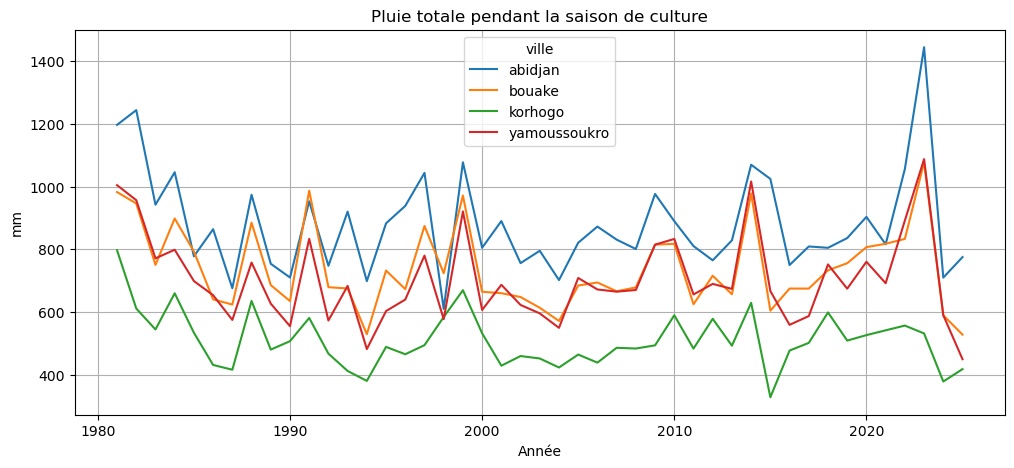

In [13]:
indic.pivot(index="YEAR", columns="ville", values="pluie_totale").plot(figsize=(12,5))
plt.title("Pluie totale pendant la saison de culture")
plt.xlabel("Année")
plt.ylabel("mm")
plt.grid(True)
plt.show()

# 8. Corrélation entre indicateurs

Si deux indicateurs sont très corrélés (proche de 1 ou de -1), ils disent presque la même chose.
On pourra n'en garder qu'un pour ne pas surcharger le modèle.

In [14]:
colonnes = ["pluie_totale", "jours_secs", "serie_seche_max", "jours_chauds",
            "tmax_moyenne", "degres_jours", "humidite_sol", "bilan_eau"]
indic[colonnes].corr().round(2)

,pluie_totale,jours_secs,serie_seche_max,jours_chauds,tmax_moyenne,degres_jours,humidite_sol,bilan_eau
pluie_totale,1.00,-0.63,-0.29,-0.76,-0.84,-0.77,0.90,0.93
jours_secs,-0.63,1.00,0.57,0.73,0.67,0.73,-0.55,-0.48
serie_seche_max,-0.29,0.57,1.00,0.35,0.30,0.35,-0.27,-0.19
jours_chauds,-0.76,0.73,0.35,1.00,0.94,0.92,-0.71,-0.53
tmax_moyenne,-0.84,0.67,0.30,0.94,1.00,0.92,-0.78,-0.67
degres_jours,-0.77,0.73,0.35,0.92,0.92,1.00,-0.73,-0.56
humidite_sol,0.90,-0.55,-0.27,-0.71,-0.78,-0.73,1.00,0.79
bilan_eau,0.93,-0.48,-0.19,-0.53,-0.67,-0.56,0.79,1.00


# 9. Sauvegarde

On sauvegarde le tableau d'indicateurs dans `data/interim/` (données en cours de traitement) au format Parquet.
Il sera ensuite joint aux rendements pour construire la table d'entraînement.

In [15]:
indic.to_parquet("../data/interim/indicateurs_climat.parquet", index=False)